# Efficient Local-Volatility Benchmark: Raw SVI, Dupire and Batched PDE

This notebook is the first **efficiency-focused but calibration-conservative** version of the preliminary local-volatility benchmark. It retains the same core modelling pipeline:

$$
\text{preliminary IvyDB cleaning}
\rightarrow \text{raw SVI slices}
\rightarrow \text{calendar-safe total variance}
\rightarrow \text{Dupire local volatility}
\rightarrow \text{Crank--Nicolson prices and deltas}.
$$

The changes are deliberately limited to those expected to preserve the hard-fought raw-SVI fit or to correct the prototype:

1. quasi-explicit SVI is used **only as one initial value** for the same final five-parameter raw-SVI optimisation;
2. the preceding maturity remains an additional warm start;
3. final optimiser tolerances are relaxed only from $10^{-11}$ to $10^{-9}$;
4. cleaned data, daily SVI parameters, Dupire grids and PDE strips are fingerprinted and cached;
5. one vector-valued PCHIP replaces 241 separate PCHIP objects without changing the interpolation;
6. one PDE solve handles all strikes of an expiry simultaneously;
7. only calls are solved and puts are recovered exactly by put--call parity;
8. local volatility is precomputed on the PDE grid and same-day PDE outputs are reused;
9. the PDE time direction, next-day frozen-model clock shift, common rate/forward curves and dividend-aware hedge accounting are corrected.

It does **not** use adaptive multistart pruning, quote downsampling, a coarser Dupire grid or a coarser PDE grid. Every retained SVI slice still receives ten fully optimised starts.

## 1. Imports, paths and visible configuration

In [3]:
from pathlib import Path
from dataclasses import dataclass
import hashlib, json, os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.interpolate import PchipInterpolator, RegularGridInterpolator
from scipy.optimize import least_squares
from scipy.stats import norm
from sklearn.isotonic import IsotonicRegression

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable=None, **kwargs):
        return iterable if iterable is not None else None

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Edit DATA_DIR only when the notebook and CSVs are not in the same folder.
DATA_DIR = Path("/mnt/data") if Path("/mnt/data").exists() else Path.cwd()

def resolve_data_file(*names):
    for name in names:
        path = DATA_DIR / name
        if path.exists(): return path
    raise FileNotFoundError(f"None of these files exists in {DATA_DIR}: {names}")

FILES = {
    "options": resolve_data_file("one_month_spx_option_price.csv", "one_month_spx_option_price(1).csv"),
    "forwards": resolve_data_file("one_month_spx_forward_price.csv", "one_month_spx_forward_price(5).csv"),
    "spot": resolve_data_file("one_month_spx_security_price.csv", "one_month_spx_security_price(3).csv"),
    "rates": resolve_data_file("one_month_spx_zero_coupon_yield_curve.csv", "one_month_spx_zero_coupon_yield_curve(3).csv"),
}
CACHE_DIR = DATA_DIR / "lv_cache_preliminary_v1"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SECID = 108105
MIN_DTE, MAX_DTE = 7, 365
MAX_ABS_LOG_MONEYNESS = 0.30
MIN_ABS_DELTA, MAX_ABS_DELTA = 0.05, 0.95
MAX_RELATIVE_SPREAD = 0.25
ATM_TIGHTER_SIDE_BAND = 0.05
MIN_POINTS_PER_SLICE = 8

K_MIN, K_MAX, N_K = -0.30, 0.30, 241
DUPIRE_WT_FLOOR, DUPIRE_G_FLOOR = 1e-7, 1e-6
LOCAL_VOL_MIN, LOCAL_VOL_MAX = 0.01, 1.50

SVI_N_STARTS = 10
SVI_MAX_NFEV = 1500
SVI_TOL = 1e-9
SVI_PENALTY_POINTS = 301
SVI_VALIDATION_POINTS = 1001

SVI_BUTTERFLY_ACCEPT_TOL = -1e-8
SVI_BUTTERFLY_PENALTY = 20.0
SVI_BUTTERFLY_REPAIR_STARTS = 3

PDE_NX = 301
PDE_NT_PER_YEAR = 900
PDE_MIN_NT = 120
PDE_X_WIDTH = 0.75
CACHE_FULL_EXPIRY_STRIP = True

EXAMPLE_DATE = None
RUN_FULL_SAME_DAY_PDE = False
RUN_ROLLING_BACKTEST = True
MAX_ROLLING_TRANSITIONS = None

FORCE_REBUILD_CLEANING = False
FORCE_RECALIBRATE_SVI = False
FORCE_REBUILD_LV = False
FORCE_REBUILD_PDE = False

CACHE_VERSION = "raw_svi_lv_efficient_v2_strict_otm_equal_weight_staged_bfly"

missing = [str(path) for path in FILES.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Edit DATA_DIR or FILES. Missing:\n" + "\n".join(missing))

## 2. Fingerprinted caches

Caching is exact reuse, not an approximation. A cache is accepted only when its fingerprint agrees with the input files and all settings that can affect the output. The SVI parameter table is written after every completed valuation date, so an interrupted run loses at most one day of work.

The first run still performs the calculation. Later runs load:

- cleaned quote and OTM tables;
- completed daily SVI parameters;
- daily repaired total-variance and local-volatility grids;
- same-day and frozen-next-day PDE strips.

In [4]:
def sha256_file(path, chunk_size=2**20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def stable_hash(obj):
    payload = json.dumps(obj, sort_keys=True, default=str, separators=(",", ":"))
    return hashlib.sha256(payload.encode()).hexdigest()

def atomic_pickle(df, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_pickle(tmp); os.replace(tmp, path)

def atomic_json(obj, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, sort_keys=True, default=str)); os.replace(tmp, path)

file_hashes = {name: sha256_file(path) for name, path in FILES.items()}
cleaning_config = {
    "version": CACHE_VERSION,
    "secid": SECID,
    "min_dte": MIN_DTE,
    "max_dte": MAX_DTE,
    "max_abs_k": MAX_ABS_LOG_MONEYNESS,
    "min_abs_delta": MIN_ABS_DELTA,
    "max_abs_delta": MAX_ABS_DELTA,
    "max_relative_spread": MAX_RELATIVE_SPREAD,
    "atm_band": ATM_TIGHTER_SIDE_BAND,
    "min_points": MIN_POINTS_PER_SLICE,
    "otm_rule": "strict_otm_tighter_near_atm_only_when_both_exist",
}

cleaning_fingerprint = stable_hash({
    "files": file_hashes,
    "config": cleaning_config,
})[:20]

svi_config = {
    "version": CACHE_VERSION,
    "n_starts": SVI_N_STARTS,
    "max_nfev": SVI_MAX_NFEV,
    "tol": SVI_TOL,
    "penalty_points": SVI_PENALTY_POINTS,
    "validation_points": SVI_VALIDATION_POINTS,
    "weighting": "equal_total_variance",
    "initialisation": "quasi_previous_maturity_generic_to_ten",
    "butterfly_strategy": "unpenalised_first_dense_validation_conditional_refit",
    "butterfly_accept_tol": SVI_BUTTERFLY_ACCEPT_TOL,
    "butterfly_penalty": SVI_BUTTERFLY_PENALTY,
    "butterfly_repair_starts": SVI_BUTTERFLY_REPAIR_STARTS,
}

svi_fingerprint = stable_hash({
    "cleaning": cleaning_fingerprint,
    "svi": svi_config,
})[:20]

CLEAN_QUOTES_CACHE = CACHE_DIR / f"quotes_{cleaning_fingerprint}.pkl"
CLEAN_OTM_CACHE = CACHE_DIR / f"otm_{cleaning_fingerprint}.pkl"
SVI_CACHE = CACHE_DIR / f"svi_{svi_fingerprint}.pkl"

print("Data directory:", DATA_DIR)
print("Cache directory:", CACHE_DIR)
print("Cleaning fingerprint:", cleaning_fingerprint)
print("SVI fingerprint:", svi_fingerprint)

Data directory: c:\Users\Startklar\ICL\NDEs\Codes\LV
Cache directory: c:\Users\Startklar\ICL\NDEs\Codes\LV\lv_cache_preliminary_v1
Cleaning fingerprint: 7968aed3bcbeee971c39
SVI fingerprint: 438536cde13609925840


## 3. Load the four IvyDB files

In [5]:
options_raw = pd.read_csv(FILES["options"], low_memory=False)
forwards_raw = pd.read_csv(FILES["forwards"], low_memory=False)
spot_raw = pd.read_csv(FILES["spot"], low_memory=False)
rates_raw = pd.read_csv(FILES["rates"], low_memory=False)
print({"options": len(options_raw), "forwards": len(forwards_raw), "spot": len(spot_raw), "rates": len(rates_raw)})

{'options': 326964, 'forwards': 1192, 'spot': 20, 'rates': 220}


## 4. Preliminary LV cleaning

This reproduces the preliminary LV universe used in the earlier repository comparison:

- SPX, European, standard unadjusted contracts;
- 7--365 calendar days to expiry;
- relative spread at most 25%;
- $0.05\leq |\Delta|\leq0.95$;
- $|\log(K/F)|\leq0.30$;
- elementary European price bounds;
- one OTM observation per strike, with the tighter side preferred near ATM.

The delta bound is a practical low-vega wing filter. It is not used as the final hedge ratio.

In [6]:
def prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw):
    options = options_raw.copy()
    options["date"] = pd.to_datetime(options["date"]); options["exdate"] = pd.to_datetime(options["exdate"])
    options["K"] = options["strike_price"] / 1000.0
    options["T_days"] = (options["exdate"] - options["date"]).dt.days; options["T"] = options["T_days"] / 365.0
    options["bid"] = pd.to_numeric(options["best_bid"], errors="coerce")
    options["ask"] = pd.to_numeric(options["best_offer"], errors="coerce")
    options["mid"] = 0.5 * (options["bid"] + options["ask"])
    options["spread"] = options["ask"] - options["bid"]
    options["relative_spread"] = options["spread"] / options["mid"].replace(0, np.nan)
    options["iv_market"] = pd.to_numeric(options["impl_volatility"], errors="coerce")
    options["delta_market"] = pd.to_numeric(options["delta"], errors="coerce")
    options["abs_delta_market"] = options["delta_market"].abs()
    mask = (
        (options["secid"] == SECID) & (options["exercise_style"] == "E") &
        (options["contract_size"] == 100) & (options["cfadj"] == 1) & options["cp_flag"].isin(["C", "P"]) &
        (options["bid"] >= 0) & (options["ask"] > options["bid"]) & (options["mid"] > 0) &
        options["T_days"].between(MIN_DTE, MAX_DTE) & options["iv_market"].between(1e-4, 5.0) &
        options["abs_delta_market"].between(MIN_ABS_DELTA, MAX_ABS_DELTA) &
        (options["relative_spread"] <= MAX_RELATIVE_SPREAD)
    )
    options = options.loc[mask].copy()

    spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
    spot["date"] = pd.to_datetime(spot["date"]); spot = spot.rename(columns={"close": "S"}).drop_duplicates("date")

    forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
    forwards["date"] = pd.to_datetime(forwards["date"]); forwards["expiration"] = pd.to_datetime(forwards["expiration"])
    forwards = forwards.rename(columns={"expiration": "exdate", "AMSettlement": "am_settlement", "ForwardPrice": "F"})
    forwards = forwards[["date", "exdate", "am_settlement", "F"]].drop_duplicates(["date", "exdate", "am_settlement"])

    rates = rates_raw.copy(); rates["date"] = pd.to_datetime(rates["date"])
    rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
    rates["rate_decimal"] = pd.to_numeric(rates["rate"], errors="coerce") / 100.0
    rate_curves = {
        d: (g["days"].to_numpy(float), g["rate_decimal"].to_numpy(float)) 
        for d, g in rates.dropna().sort_values(["date", "days"]).groupby("date")
    }

    options = options.merge(
        spot, on="date", how="left").merge(
        forwards, on=["date", "exdate", "am_settlement"], how="left", validate="many_to_one"
    )
    options["r"] = [float(np.interp(n, *rate_curves[d])) 
                    if d in rate_curves else np.nan for d, n in zip(options["date"], options["T_days"])
                ]
    options["D"] = np.exp(-options["r"] * options["T"])
    options["carry"] = np.log(options["F"] / options["S"]) / options["T"]
    options["q"] = options["r"] - options["carry"]
    options["k"] = np.log(options["K"] / options["F"])
    options = options.dropna(subset=["S", "F", "r", "D", "carry", "k"])
    options = options.loc[options["k"].abs() <= MAX_ABS_LOG_MONEYNESS].copy()

    call_lb = options["D"] * np.maximum(options["F"] - options["K"], 0.0)
    call_ub = options["D"] * options["F"]
    put_lb = options["D"] * np.maximum(options["K"] - options["F"], 0.0)
    put_ub = options["D"] * options["K"]
    lb = np.where(options["cp_flag"].eq("C"), call_lb, put_lb)
    ub = np.where(options["cp_flag"].eq("C"), call_ub, put_ub)
    options = options.loc[(options["mid"] >= lb - 1e-6) & (options["mid"] <= ub + 1e-6)].copy()
    return options.sort_values(["date", "exdate", "am_settlement", "K", "cp_flag"]).reset_index(drop=True)


def build_otm_surface(quotes):
    idx = [
        "date", "exdate", "am_settlement", "K", "T",
        "S", "F", "r", "q", "carry", "D", "k",
    ]
    vals = [
        "mid", "bid", "ask", "spread", "relative_spread",
        "iv_market", "delta_market", "optionid",
    ]

    wide = quotes.pivot_table(
        index=idx,
        columns="cp_flag",
        values=vals,
        aggfunc="first",
    )
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()

    strict_call = wide["K"] >= wide["F"]
    near = wide["k"].abs() <= ATM_TIGHTER_SIDE_BAND

    have_c = wide.get(
        "iv_market_C", pd.Series(np.nan, index=wide.index)
    ).notna()
    have_p = wide.get(
        "iv_market_P", pd.Series(np.nan, index=wide.index)
    ).notna()

    c_spread = wide.get(
        "spread_C", pd.Series(np.inf, index=wide.index)
    )
    p_spread = wide.get(
        "spread_P", pd.Series(np.inf, index=wide.index)
    )

    # Away from ATM: strict call above F, strict put below F.
    # Near ATM: use the tighter side only when both quotes exist.
    # Never substitute an ITM quote merely because the OTM quote is missing.
    choose_call = strict_call.copy()
    both_near = near & have_c & have_p
    choose_call = np.where(
        both_near,
        c_spread <= p_spread,
        choose_call,
    )

    wide["cp_otm"] = np.where(choose_call, "C", "P")

    for base in vals:
        c = wide.get(
            f"{base}_C", pd.Series(np.nan, index=wide.index)
        )
        p = wide.get(
            f"{base}_P", pd.Series(np.nan, index=wide.index)
        )
        wide[f"{base}_otm"] = np.where(choose_call, c, p)

    # Missing selected OTM quotes are dropped rather than replaced by ITM quotes.
    wide = wide.dropna(
        subset=["iv_market_otm", "mid_otm"]
    ).copy()

    wide["w_market"] = wide["iv_market_otm"]**2 * wide["T"]

    # Reproduce the reference raw-SVI specification:
    # equal weighting in total-variance space.
    wide["fit_weight"] = 1.0

    sizes = wide.groupby(
        ["date", "exdate", "am_settlement"]
    ).size()
    valid = sizes[
        sizes >= MIN_POINTS_PER_SLICE
    ].index

    return (
        wide.set_index(
            ["date", "exdate", "am_settlement"]
        )
        .loc[valid]
        .reset_index()
        .sort_values(["date", "T", "k"])
        .reset_index(drop=True)
    )

if CLEAN_QUOTES_CACHE.exists() and CLEAN_OTM_CACHE.exists() and not FORCE_REBUILD_CLEANING:
    quotes_all = pd.read_pickle(CLEAN_QUOTES_CACHE); otm = pd.read_pickle(CLEAN_OTM_CACHE)
    print("Loaded cleaned-data cache.")
else:
    quotes_all = prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw)
    otm = build_otm_surface(quotes_all)
    atomic_pickle(quotes_all, CLEAN_QUOTES_CACHE); atomic_pickle(otm, CLEAN_OTM_CACHE)
    print("Built and cached cleaned data.")

print(
    "Quotes:", len(quotes_all), 
    "OTM observations:", len(otm), 
    "Slices:", otm.groupby(["date", "exdate", "am_settlement"]).ngroups
)

Loaded cleaned-data cache.
Quotes: 192031 OTM observations: 91930 Slices: 809


## 5. Black--Scholes convention check

Before fitting SVI, the supplied market implied volatility is put back into forward Black--Scholes. The residual is a convention and data-alignment floor rather than a model-fitting error.

In [7]:
def bs_forward_price(cp_flag, F, K, T, D, sigma):
    F, K, T, D, sigma = np.broadcast_arrays(*map(lambda x: np.asarray(x, float), [F, K, T, D, sigma]))
    volT = np.maximum(sigma, 1e-12) * np.sqrt(np.maximum(T, 1e-16))
    d1 = (np.log(np.maximum(F, 1e-300) / np.maximum(K, 1e-300)) + 0.5 * volT**2) / volT
    d2 = d1 - volT
    call = D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    put = D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))
    return np.where(np.asarray(cp_flag) == "C", call, put)

quotes_all["bs_market_iv_price"] = bs_forward_price(
    quotes_all["cp_flag"], quotes_all["F"], quotes_all["K"], quotes_all["T"], quotes_all["D"], quotes_all["iv_market"]
)

quotes_all["market_iv_repricing_error"] = quotes_all["bs_market_iv_price"] - quotes_all["mid"]
print("Market-IV repricing MAE:", quotes_all["market_iv_repricing_error"].abs().mean())

Market-IV repricing MAE: 0.14517807990320855


## 6. Raw SVI and the quasi-explicit initial value

The final slice model remains unrestricted raw SVI:

$$
w(k)=a+b\left[\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}\right].
$$

For fixed $(m,\sigma)$, write

$$
w(k)=a+p(k-m)+q\sqrt{(k-m)^2+\sigma^2},\qquad p=b\rho,\ q=b.
$$

Then $(a,p,q)$ are obtained by weighted linear least squares. A cheap two-dimensional search over $(m,\sigma)$ produces a high-quality **initial value only**. That candidate is then refined by the same five-dimensional constrained raw-SVI optimisation as every other start. It therefore does not reduce the final model class.

Every slice still receives exactly ten fully optimised starts: quasi-explicit, the previous maturity when available, and enough generic starts to reach ten.

In [8]:
def svi_raw_w(k, a, b, rho, m, sigma):
    z = np.asarray(k, float) - m
    return a + b * (rho * z + np.sqrt(z*z + sigma*sigma))

def svi_minimum(a, b, rho, sigma):
    return a + b * sigma * np.sqrt(max(1.0 - rho*rho, 0.0))

def svi_from_unconstrained(x):
    w_min, b, rho, m, sigma = np.exp(x[0]), np.exp(x[1]), np.tanh(x[2]), x[3], np.exp(x[4])
    a = w_min - b * sigma * np.sqrt(max(1.0 - rho*rho, 1e-14))
    return a, b, rho, m, sigma

def unconstrained_from_svi(a, b, rho, m, sigma):
    return np.array([
        np.log(max(svi_minimum(a, b, rho, sigma), 1e-8)), 
        np.log(max(b, 1e-8)), 
        np.arctanh(np.clip(rho, -0.995, 0.995)), 
        m, 
        np.log(max(sigma, 1e-6))
    ])

def svi_derivatives(k, a, b, rho, m, sigma):
    z = np.asarray(k, float) - m; root = np.sqrt(z*z + sigma*sigma)
    return b * (rho + z / root), b * sigma*sigma / np.maximum(root**3, 1e-18)

def gatheral_g(k, w, wk, wkk):
    w = np.maximum(np.asarray(w, float), 1e-12)
    return (1.0 - np.asarray(k) * wk / (2.0*w))**2 - 0.25 * wk*wk * (1.0/w + 0.25) + 0.5 * wkk

def quasi_explicit_coefficients(k, w, weight, m, sigma):
    z = k - m; root = np.sqrt(z*z + sigma*sigma)
    X = np.column_stack([np.ones_like(k), z, root]); sw = np.sqrt(weight)
    a, p, q = np.linalg.lstsq(X * sw[:, None], w * sw, rcond=None)[0]
    q = max(float(q), 1e-8); p = float(np.clip(p, -0.995*q, 0.995*q))
    b, rho = q, p / q
    a += max(1e-8 - svi_minimum(a, b, rho, sigma), 0.0)
    return a, b, rho, m, sigma

def quasi_explicit_start(k, w, weight):
    x0 = np.array([float(np.median(k)), np.log(0.15)])

    def resid(x):
        m, sigma = x[0], np.exp(x[1])
        return np.sqrt(weight) * (svi_raw_w(k, *quasi_explicit_coefficients(k, w, weight, m, sigma)) - w)
    
    res = least_squares(
        resid, 
        x0, 
        bounds=([K_MIN - 0.3, np.log(1e-3)], [K_MAX + 0.3, np.log(2.0)]), 
        max_nfev=250, 
        xtol=1e-8, 
        ftol=1e-8, 
        gtol=1e-8)
    
    return unconstrained_from_svi(*quasi_explicit_coefficients(k, w, weight, res.x[0], np.exp(res.x[1])))

## 7. Conservative ten-start calibration

The efficiency changes here are intentionally modest:

- the quasi-explicit candidate replaces one generic candidate rather than adding an eleventh full run;
- the preceding maturity remains a warm start;
- $10^{-9}$ replaces $10^{-11}$, which is still far tighter than the economic precision of bid--ask midpoints;
- all ten candidates are fully polished, and the best complete penalised objective is retained.

The 301-point butterfly penalty grid is unchanged. A denser 1,001-point grid is used for final diagnostics.

In [9]:
def fit_svi_slice(g, previous=None):
    g = g.sort_values("k")
    k = g["k"].to_numpy(float)
    w = g["w_market"].to_numpy(float)
    weight = g["fit_weight"].to_numpy(float)
    sqrt_weight = np.sqrt(weight)

    atm = float(np.interp(0.0, k, w))
    k_med = float(np.median(k))

    starts = [("quasi_explicit", quasi_explicit_start(k, w, weight))]

    if previous is not None:
        x_prev = unconstrained_from_svi(
            previous["a"],
            previous["b"],
            previous["rho"],
            previous["m"],
            previous["sigma"],
        )
        starts.append(("previous_maturity", x_prev))

    generic = []
    for rho0 in (-0.85, -0.60, -0.30):
        for sig0 in (0.05, 0.15, 0.30):
            b0 = max(0.02, 0.25 * np.nanstd(w) / max(np.nanstd(k), 1e-3))
            a0 = (max(0.5 * atm, 1e-6) - b0 * sig0 * np.sqrt(1.0 - rho0*rho0))
            generic.append((
                f"generic_rho{rho0}_sig{sig0}",
                unconstrained_from_svi(a0, b0, rho0, k_med, sig0)
            ))

    starts.extend(generic[:max(SVI_N_STARTS - len(starts), 0)])
    starts = starts[:SVI_N_STARTS]

    k_pen = np.linspace(K_MIN, K_MAX, SVI_PENALTY_POINTS)
    k_val = np.linspace(K_MIN, K_MAX, SVI_VALIDATION_POINTS)

    def data_and_slope_residual(x):
        a, b, rho, m, sigma = svi_from_unconstrained(x)

        data = sqrt_weight * (svi_raw_w(k, a, b, rho, m, sigma) - w)

        slopes = 10.0 * np.array([max(b*(1-rho) - 1.98, 0.0), max(b*(1+rho) - 1.98, 0.0)])

        return np.concatenate([data, slopes])

    def repaired_residual(x, penalty):
        a, b, rho, m, sigma = svi_from_unconstrained(x)

        wp = svi_raw_w(k_pen, a, b, rho, m, sigma)
        wkp, wkkp = svi_derivatives(k_pen, a, b, rho, m, sigma)

        butterfly = penalty * np.minimum(gatheral_g(k_pen, wp, wkp, wkkp), 0.0)

        return np.concatenate([data_and_slope_residual(x), butterfly])

    def dense_metrics(res):
        a, b, rho, m, sigma = svi_from_unconstrained(res.x)

        w_fit = svi_raw_w(k, a, b, rho, m, sigma)
        w_val = svi_raw_w(k_val, a, b, rho, m, sigma)
        wk_val, wkk_val = svi_derivatives(k_val, a, b, rho, m, sigma)

        return {
            "params": (a, b, rho, m, sigma),
            "sse_w": float(np.sum(weight * (w_fit - w)**2)),
            "min_g": float(np.min(gatheral_g(k_val, w_val, wk_val, wkk_val)))
        }

    def run_starts(residual, labelled_starts):
        candidates = []
        total_nfev = 0

        for label, x0 in labelled_starts:
            try:
                res = least_squares(
                    residual,
                    x0=x0,
                    max_nfev=SVI_MAX_NFEV,
                    xtol=SVI_TOL,
                    ftol=SVI_TOL,
                    gtol=SVI_TOL,
                )

                total_nfev += int(res.nfev)
                candidates.append((float(2.0 * res.cost), label, res, dense_metrics(res)))

            except Exception:
                continue

        if not candidates:
            raise RuntimeError("All SVI starts failed.")

        return (sorted(candidates, key=lambda item: item[0]), total_nfev)

    # Stage 1: fit the market data without a butterfly penalty.
    data_candidates, total_nfev = run_starts(data_and_slope_residual, starts)

    _, label, res, metrics = data_candidates[0]
    butterfly_refit = False
    repair_penalty = 0.0

    # Stage 2: only problematic slices receive a butterfly-penalised refit.
    if metrics["min_g"] < SVI_BUTTERFLY_ACCEPT_TOL:
        butterfly_refit = True

        repair_seeds = [
            (f"repair_from_{lab}", candidate_res.x)
            for _, lab, candidate_res, _
            in data_candidates[:SVI_BUTTERFLY_REPAIR_STARTS]
        ]

        repair_candidates, repair_nfev = run_starts(
            lambda x: repaired_residual(x, SVI_BUTTERFLY_PENALTY), repair_seeds
        )

        total_nfev += repair_nfev

        feasible = [
            item for item in repair_candidates
            if item[3]["min_g"]
            >= SVI_BUTTERFLY_ACCEPT_TOL
        ]

        if feasible:
            chosen = min(feasible, key=lambda item: item[3]["sse_w"])
        else:
            chosen = repair_candidates[0]

        _, label, res, metrics = chosen
        repair_penalty = SVI_BUTTERFLY_PENALTY

    a, b, rho, m, sigma = metrics["params"]

    final_penalised_score = float(np.sum(repaired_residual(res.x, SVI_BUTTERFLY_PENALTY)**2))

    return {
        "a": a,
        "b": b,
        "rho": rho,
        "m": m,
        "sigma": sigma,
        "n": len(g),
        "sse_w": metrics["sse_w"],
        "penalised_score": final_penalised_score,
        "min_g_dense": metrics["min_g"],
        "left_slope": b*(1-rho),
        "right_slope": b*(1+rho),
        "success": bool(res.success),
        "best_start": label,
        "n_starts": len(starts),
        "total_nfev": total_nfev,
        "butterfly_refit": butterfly_refit,
        "repair_penalty": repair_penalty,
    }


def calibrate_day_svi(day_otm, progress=None):
    rows = []; previous = None
    for (exdate, am_settlement), g in day_otm.groupby(["exdate", "am_settlement"], sort=True):
        try:
            fit = fit_svi_slice(g, previous)
            fit.update({
                "date": g["date"].iloc[0], 
                "exdate": exdate, 
                "am_settlement": am_settlement, 
                "T": float(g["T"].iloc[0]), 
                "F": float(g["F"].iloc[0]), 
                "D": float(g["D"].iloc[0]), 
                "r": float(g["r"].iloc[0]), 
                "carry": float(g["carry"].iloc[0])
            })
            rows.append(fit); previous = fit
        except Exception as exc:
            print(f"Skipping {exdate} AM={am_settlement}: {exc}")
        if progress is not None: progress.update(1)

    return pd.DataFrame(rows).sort_values("T").reset_index(drop=True) if rows else pd.DataFrame()

## 8. Incremental daily SVI cache

A completed date is written immediately. Rerunning the cell loads all cached dates and calibrates only missing ones. Set `FORCE_RECALIBRATE_SVI=True` only when deliberately replacing the cache for the current fingerprint.

In [10]:
if SVI_CACHE.exists() and not FORCE_RECALIBRATE_SVI:
    svi_params = pd.read_pickle(SVI_CACHE)
    print("Loaded", len(svi_params), "cached slices.")
else:
    svi_params = pd.DataFrame()

all_dates = list(pd.to_datetime(sorted(otm["date"].unique())))
done_dates = set(pd.to_datetime(svi_params["date"].unique())) if len(svi_params) else set()
remaining_slices = otm.loc[~otm["date"].isin(done_dates)].groupby(["date", "exdate", "am_settlement"]).ngroups

with tqdm(total=remaining_slices, desc="Calibrating and caching raw SVI", unit="slice") as progress:
    for date in all_dates:
        if date in done_dates: continue
        fitted = calibrate_day_svi(otm.loc[otm["date"] == date], progress)
        if len(fitted):
            svi_params = pd.concat([svi_params, fitted], ignore_index=True)
            svi_params = svi_params.drop_duplicates(["date", "exdate", "am_settlement"], keep="last").sort_values(["date", "T"])
            atomic_pickle(svi_params, SVI_CACHE)

if svi_params.empty: raise RuntimeError("No SVI slices were fitted.")
print("Total fitted SVI slices:", len(svi_params), "Cache:", SVI_CACHE.name)

Loaded 809 cached slices.


Calibrating and caching raw SVI: 0slice [00:00, ?slice/s]

Total fitted SVI slices: 809 Cache: svi_438536cde13609925840.pkl


In [11]:
butterfly_bad = (svi_params["min_g_dense"] < SVI_BUTTERFLY_ACCEPT_TOL)

print("Slices requiring butterfly refit:", svi_params["butterfly_refit"].mean())

print("Slices still below dense g tolerance:", butterfly_bad.mean())

display(
    svi_params.loc[
        butterfly_bad,
        [
            "date",
            "exdate",
            "min_g_dense",
            "sse_w",
            "best_start",
        ],
    ].head(20)
)

Slices requiring butterfly refit: 0.004944375772558714
Slices still below dense g tolerance: 0.0


,date,exdate,min_g_dense,sse_w,best_start


## 9. Same-day raw-SVI fit

In [12]:
def add_same_day_svi_fit(otm_df, params_df):
    key = ["date", "exdate", "am_settlement"]
    cols = key + ["a", "b", "rho", "m", "sigma"]
    out = otm_df.merge(params_df[cols], on=key, how="inner", validate="many_to_one")
    out["w_svi"] = svi_raw_w(out["k"], out["a"], out["b"], out["rho"], out["m"], out["sigma"])
    out["iv_svi"] = np.sqrt(np.maximum(out["w_svi"], 1e-12) / out["T"])
    out["price_svi_bs"] = bs_forward_price(out["cp_otm"], out["F"], out["K"], out["T"], out["D"], out["iv_svi"])
    out["pricing_error_svi"] = out["price_svi_bs"] - out["mid_otm"]
    out["inside_spread_svi"] = out["price_svi_bs"].between(out["bid_otm"], out["ask_otm"])
    return out

same_day_svi = add_same_day_svi_fit(otm, svi_params)
same_day_summary = pd.Series({
    "n": len(same_day_svi), "RMSE": np.sqrt(np.mean(same_day_svi["pricing_error_svi"]**2)),
    "MAE": same_day_svi["pricing_error_svi"].abs().mean(), "inside_bid_ask": same_day_svi["inside_spread_svi"].mean(),
})
display(same_day_summary.to_frame("raw_SVI"))

,raw_SVI
n,91930.000000
RMSE,1.656070
MAE,0.905370
inside_bid_ask,0.408942


## 10. Vector-valued calendar-safe total variance

The modelling choices are unchanged: evaluate all raw-SVI slices on a common $k$-grid, apply isotonic regression in maturity at each $k$, impose a tiny strictly positive maturity slope and interpolate with PCHIP.

The efficiency change is purely structural. `PchipInterpolator(..., axis=0)` creates one vector-valued interpolator for the whole $(T,k)$ matrix instead of 241 Python objects. It returns the same componentwise PCHIP construction up to floating-point round-off.

In [13]:
class SmoothTotalVarianceSurface:
    def __init__(self, params_day, k_grid=None):
        params = params_day.sort_values("T").copy()
        if params["T"].duplicated().any():
            params = params.sort_values("n", ascending=False).drop_duplicates("T").sort_values("T")
        self.params = params.reset_index(drop=True)
        self.T_nodes = self.params["T"].to_numpy(float)
        self.k_grid = np.linspace(K_MIN, K_MAX, N_K) if k_grid is None else np.asarray(k_grid, float)
        raw = np.vstack([svi_raw_w(self.k_grid, row.a, row.b, row.rho, row.m, row.sigma) for row in self.params.itertuples()])
        ir = IsotonicRegression(increasing=True, out_of_bounds="clip"); iso = np.empty_like(raw)
        for j in range(raw.shape[1]): iso[:, j] = ir.fit_transform(self.T_nodes, raw[:, j])
        for i in range(1, len(self.T_nodes)):
            iso[i] = np.maximum(iso[i], iso[i-1] + DUPIRE_WT_FLOOR * (self.T_nodes[i] - self.T_nodes[i-1]))
        self.W_nodes = iso
        self._pchip = PchipInterpolator(self.T_nodes, self.W_nodes, axis=0, extrapolate=False)
        self._pchip_d1 = self._pchip.derivative()

    def on_k_grid(self, T, derivative=0):
        T = np.clip(np.atleast_1d(np.asarray(T, float)), self.T_nodes[0], self.T_nodes[-1])
        return self._pchip(T) if derivative == 0 else self._pchip_d1(T)

    def pairwise(self, T, k, derivative=0):
        T, k = np.broadcast_arrays(np.asarray(T, float), np.asarray(k, float)); values = self.on_k_grid(T.ravel(), derivative)
        ans = np.fromiter((np.interp(kk, self.k_grid, values[i]) for i, kk in enumerate(k.ravel())), float, count=k.size)
        return ans.reshape(T.shape)

    def dense_grids(self, T_grid=None):
        if T_grid is None:
            T_grid = np.unique(np.concatenate([self.T_nodes, np.linspace(self.T_nodes[0], self.T_nodes[-1], max(80, 4*len(self.T_nodes))) ]))
        W = self.on_k_grid(T_grid, 0); WT = self.on_k_grid(T_grid, 1)
        WK = np.gradient(W, self.k_grid, axis=1, edge_order=2); WKK = np.gradient(WK, self.k_grid, axis=1, edge_order=2)
        return np.asarray(T_grid), self.k_grid, W, WT, WK, WKK

## 11. Dupire grid and daily surface cache

Dupire uses

$$
\sigma_{\mathrm{loc}}^2(T,k)=\frac{w_T(T,k)}{g(T,k)}.
$$

The repaired total-variance grid, derivatives, butterfly function and clipped local-volatility grid are cached per date. The cache key also hashes that date's fitted SVI parameters, so changing a calibration automatically creates a new surface cache.

In [14]:
class LocalVolSurface:
    def __init__(self, T_grid, k_grid, W, WT, WK, WKK, G, sigma_grid, diagnostics=None):
        self.T_grid, self.k_grid = np.asarray(T_grid), np.asarray(k_grid)
        self.W, self.WT, self.WK, self.WKK, self.G, self.sigma_grid = W, WT, WK, WKK, G, sigma_grid
        self.diagnostics = diagnostics if diagnostics is not None else {}
        self.interpolator = RegularGridInterpolator((self.T_grid, self.k_grid), self.sigma_grid, bounds_error=False, fill_value=None)

    @classmethod
    def from_total_variance(cls, tv):
        T, k, W, WT, WK, WKK = tv.dense_grids(); G = gatheral_g(k[None, :], W, WK, WKK)
        sigma = np.sqrt(np.clip(np.maximum(WT, DUPIRE_WT_FLOOR) / np.maximum(G, DUPIRE_G_FLOOR), LOCAL_VOL_MIN**2, LOCAL_VOL_MAX**2))
        diagnostics = {
            "min_w": float(np.nanmin(W)), "min_wT_raw": float(np.nanmin(WT)), "fraction_wT_floored": float(np.mean(WT < DUPIRE_WT_FLOOR)),
            "min_g_raw": float(np.nanmin(G)), "fraction_g_floored": float(np.mean(G < DUPIRE_G_FLOOR)),
            "min_sigma": float(np.nanmin(sigma)), "max_sigma": float(np.nanmax(sigma)),
            "fraction_sigma_floor": float(np.mean(sigma <= LOCAL_VOL_MIN + 1e-12)), "fraction_sigma_cap": float(np.mean(sigma >= LOCAL_VOL_MAX - 1e-12)),
        }
        return cls(T, k, W, WT, WK, WKK, G, sigma, diagnostics)

    def sigma_tk(self, T, k):
        T, k = np.broadcast_arrays(np.asarray(T, float), np.asarray(k, float))
        pts = np.column_stack([np.clip(T.ravel(), self.T_grid[0], self.T_grid[-1]), np.clip(k.ravel(), self.k_grid[0], self.k_grid[-1])])
        return self.interpolator(pts).reshape(T.shape)

    def sigma_abs(self, absolute_time, S, calibration_curve):
        absolute_time, S = np.broadcast_arrays(np.asarray(absolute_time, float), np.asarray(S, float))
        k = np.log(np.maximum(S, 1e-300) / np.maximum(calibration_curve.forward(absolute_time), 1e-300))
        return self.sigma_tk(absolute_time, k)

def hash_params(params_day):
    cols = ["date", "exdate", "am_settlement", "T", "a", "b", "rho", "m", "sigma"]
    return hashlib.sha256(pd.util.hash_pandas_object(params_day[cols], index=False).values.tobytes()).hexdigest()[:16]

def lv_cache_path(date, params_day):
    cfg = stable_hash({"clean": cleaning_fingerprint, "svi": svi_fingerprint, "params": hash_params(params_day), "k": [K_MIN, K_MAX, N_K], "floors": [DUPIRE_WT_FLOOR, DUPIRE_G_FLOOR, LOCAL_VOL_MIN, LOCAL_VOL_MAX]})[:16]
    return CACHE_DIR / f"lv_{pd.Timestamp(date):%Y%m%d}_{cfg}.npz"

LV_MEMORY_CACHE = {}
def build_lv_for_date(date):
    date = pd.Timestamp(date)
    if date in LV_MEMORY_CACHE and not FORCE_REBUILD_LV: return LV_MEMORY_CACHE[date]
    params = svi_params.loc[svi_params["date"] == date].copy()
    if params["T"].nunique() < 2: raise ValueError("At least two distinct maturities are required for Dupire.")
    path = lv_cache_path(date, params)
    if path.exists() and not FORCE_REBUILD_LV:
        z = np.load(path, allow_pickle=False); diagnostics = json.loads(str(z["diagnostics_json"].item()))
        lv = LocalVolSurface(z["T"], z["k"], z["W"], z["WT"], z["WK"], z["WKK"], z["G"], z["sigma"], diagnostics)
    else:
        lv = LocalVolSurface.from_total_variance(SmoothTotalVarianceSurface(params))
        np.savez_compressed(path, T=lv.T_grid, k=lv.k_grid, W=lv.W, WT=lv.WT, WK=lv.WK, WKK=lv.WKK, G=lv.G, sigma=lv.sigma_grid, diagnostics_json=json.dumps(lv.diagnostics))
    LV_MEMORY_CACHE[date] = lv
    return lv

## 12. Common daily discount and forward curves

The prototype treated each option's maturity-average rate and carry as constant over its entire PDE. This version constructs one coherent curve per valuation date and settlement type.

Let $D_d(u)$ be the discount factor and $F_d(u)$ the forward observed on valuation date $d$ for horizon $u$. PCHIP is applied to $\log D_d(u)$ and $\log(F_d(u)/S_d)$. Then

$$
r_d(u)=-\partial_u\log D_d(u),\qquad c_d(u)=\partial_u\log\frac{F_d(u)}{S_d},\qquad q_d(u)=r_d(u)-c_d(u).
$$

The day-$t$ volatility function remains frozen for the prediction, while the next day's observable discount and forward curves are used for next-day repricing.

In [15]:
@dataclass
class DailyMarketCurve:
    date: pd.Timestamp
    am_settlement: int
    spot: float
    T_nodes: np.ndarray
    logD_nodes: np.ndarray
    logF_nodes: np.ndarray

    def __post_init__(self):
        self._logD = PchipInterpolator(self.T_nodes, self.logD_nodes, extrapolate=True)
        self._logF = PchipInterpolator(self.T_nodes, self.logF_nodes, extrapolate=True)
        self._r = self._logD.derivative(); self._carry = self._logF.derivative()

    def log_discount(self, t): return self._logD(np.maximum(np.asarray(t, float), 0.0))
    def log_forward_ratio(self, t): return self._logF(np.maximum(np.asarray(t, float), 0.0))
    def discount(self, t0, t1): return np.exp(self.log_discount(t1) - self.log_discount(t0))
    def carry_growth(self, t0, t1): return np.exp(self.log_forward_ratio(t1) - self.log_forward_ratio(t0))
    def dividend_discount(self, t0, t1): return self.discount(t0, t1) * self.carry_growth(t0, t1)
    def r_inst(self, t): return -self._r(np.maximum(np.asarray(t, float), 0.0))
    def carry_inst(self, t): return self._carry(np.maximum(np.asarray(t, float), 0.0))
    def q_integral(self, t0, t1): return -(self.log_discount(t1) - self.log_discount(t0)) - (self.log_forward_ratio(t1) - self.log_forward_ratio(t0))
    def forward(self, t): return self.spot * np.exp(self.log_forward_ratio(t))

class CurveBook:
    def __init__(self, spot_raw, forwards_raw, rates_raw):
        self.spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
        self.spot["date"] = pd.to_datetime(self.spot["date"]); self.spot = self.spot.set_index("date")["close"].to_dict()
        self.forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
        self.forwards["date"] = pd.to_datetime(self.forwards["date"]); self.forwards["expiration"] = pd.to_datetime(self.forwards["expiration"])
        self.rates = rates_raw.copy(); self.rates["date"] = pd.to_datetime(self.rates["date"])
        self.rates["rate_decimal"] = pd.to_numeric(self.rates["rate"], errors="coerce") / 100.0
        self._cache = {}

    def get(self, date, am_settlement):
        date, am = pd.Timestamp(date), int(am_settlement); key = (date, am)
        if key in self._cache: return self._cache[key]
        S0 = float(self.spot[date])
        rg = self.rates.loc[self.rates["date"] == date, ["days", "rate_decimal"]].dropna().sort_values("days")
        T_r = rg["days"].to_numpy(float) / 365.0; logD = -rg["rate_decimal"].to_numpy(float) * T_r
        fg = self.forwards.loc[(self.forwards["date"] == date) & (self.forwards["AMSettlement"] == am), ["expiration", "ForwardPrice"]].copy()
        if len(fg) < 2: fg = self.forwards.loc[self.forwards["date"] == date, ["expiration", "ForwardPrice"]].copy()
        fg["T"] = (fg["expiration"] - date).dt.days / 365.0
        fg = fg.loc[(fg["T"] >= 0) & (fg["ForwardPrice"] > 0)].groupby("T", as_index=False)["ForwardPrice"].mean().sort_values("T")
        T_f = fg["T"].to_numpy(float); logF = np.log(fg["ForwardPrice"].to_numpy(float) / S0)
        positive_f = T_f > 0; T_f, logF = T_f[positive_f], logF[positive_f]
        T_all = np.unique(np.concatenate([[0.0], T_r, T_f]))
        logD_all = np.interp(T_all, np.r_[0.0, T_r], np.r_[0.0, logD])
        logF_all = np.interp(T_all, np.r_[0.0, T_f], np.r_[0.0, logF])
        curve = DailyMarketCurve(date, am, S0, T_all, logD_all, logF_all)
        self._cache[key] = curve
        return curve

curve_book = CurveBook(spot_raw, forwards_raw, rates_raw)

## 13. Example-date surface diagnostics

In [16]:
dates = sorted(pd.to_datetime(svi_params["date"].unique()))
example_date = pd.Timestamp(EXAMPLE_DATE) if EXAMPLE_DATE is not None else dates[0]
lv_example = build_lv_for_date(example_date)
print("Example date:", example_date.date())
display(pd.Series(lv_example.diagnostics).to_frame("value"))

Example date: 2024-03-01


,value
min_w,3.651299e-04
min_wT_raw,4.553871e-08
fraction_wT_floored,3.739102e-02
min_g_raw,-8.744038e-02
fraction_g_floored,6.993333e-05
min_sigma,1.000000e-02
max_sigma,1.500000e+00
fraction_sigma_floor,6.925731e-02
fraction_sigma_cap,4.662222e-05


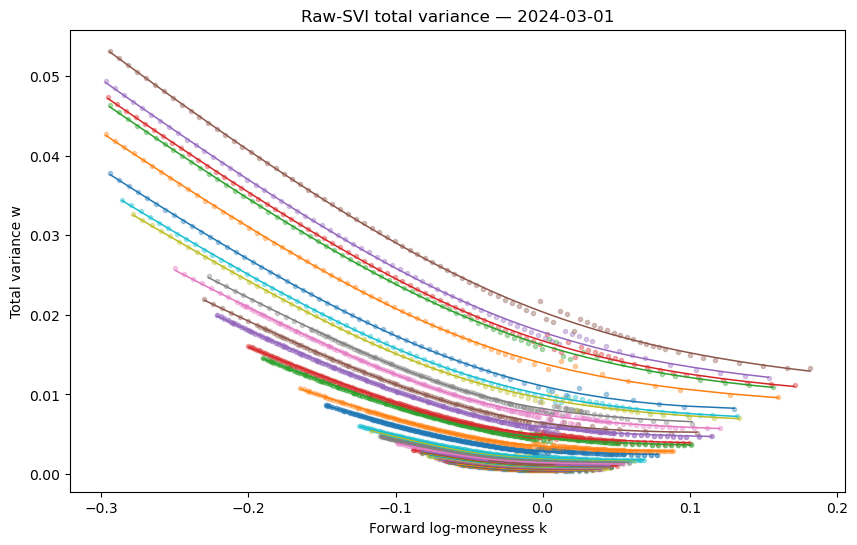

In [17]:
day_otm = same_day_svi.loc[same_day_svi["date"] == example_date]
fig, ax = plt.subplots(figsize=(10, 6))
for T, g in day_otm.groupby("T"):
    ax.scatter(g["k"], g["w_market"], s=9, alpha=0.35)
    order = np.argsort(g["k"].to_numpy()); ax.plot(g["k"].to_numpy()[order], g["w_svi"].to_numpy()[order], lw=1.1)
ax.set(title=f"Raw-SVI total variance — {example_date.date()}", xlabel="Forward log-moneyness k", ylabel="Total variance w")
plt.show()

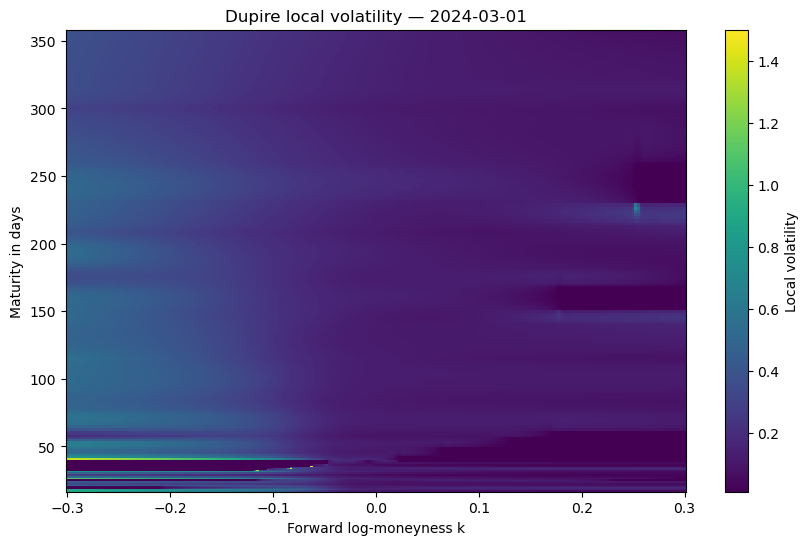

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(lv_example.k_grid, lv_example.T_grid * 365, lv_example.sigma_grid, shading="auto")
fig.colorbar(mesh, ax=ax, label="Local volatility")
ax.set(title=f"Dupire local volatility — {example_date.date()}", xlabel="Forward log-moneyness k", ylabel="Maturity in days")
plt.show()

## 14. Correct-clock batched Crank--Nicolson solver

For one expiry, the PDE operator is independent of strike. All call payoffs are therefore stored as columns of one matrix and propagated through the same tridiagonal systems. This solves the same finite-difference equations as separate strike-by-strike runs, but removes repeated construction and time stepping.

If the pricing origin is $\delta$ years after the calibration date, the frozen volatility is evaluated at absolute model time

$$
\delta+s,
$$

not restarted at $s$. During backward stepping the coefficient is evaluated at the actual midpoint $s$, correcting the prototype's reversed local-volatility clock.

Puts are recovered from

$$
P=C-SQ(0,T)+KD(0,T),\qquad \Delta_P=\Delta_C-Q(0,T),
$$

where $Q(0,T)$ is the dividend discount factor.

In [19]:
def thomas_solve_many(lower, diag, upper, rhs):
    lower, diag, upper, rhs = map(lambda x: np.asarray(x, float).copy(), [lower, diag, upper, rhs])
    for i in range(1, len(diag)):
        mult = lower[i] / diag[i-1]; diag[i] -= mult * upper[i-1]; rhs[i] -= mult * rhs[i-1]
    out = np.empty_like(rhs); out[-1] = rhs[-1] / diag[-1]
    for i in range(len(diag)-2, -1, -1): out[i] = (rhs[i] - upper[i] * out[i+1]) / diag[i]
    return out

def pde_call_strip(lv, calibration_curve, pricing_curve, strikes, T, time_origin=0.0, nx=PDE_NX, nt=None, x_width=PDE_X_WIDTH):
    strikes = np.asarray(sorted(np.unique(strikes)), float); T = float(T)
    if T <= 0 or len(strikes) == 0: raise ValueError("Positive maturity and at least one strike are required.")
    nt = max(PDE_MIN_NT, int(np.ceil(PDE_NT_PER_YEAR * T))) if nt is None else int(nt)
    nx += (nx % 2 == 0)
    x = np.linspace(-x_width, x_width, nx); S0 = pricing_curve.spot; S = S0 * np.exp(x)
    dx, dt = x[1] - x[0], T / nt; mid = nx // 2
    V = np.maximum(S[:, None] - strikes[None, :], 0.0)

    s_mid = T - (np.arange(nt) + 0.5) * dt
    sigma_grid = lv.sigma_abs(time_origin + s_mid[:, None], S[None, :], calibration_curve)
    r_mid = np.asarray(pricing_curve.r_inst(s_mid), float)
    c_mid = np.asarray(pricing_curve.carry_inst(s_mid), float)
    inv_dx, inv_dx2 = 1.0 / dx, 1.0 / dx**2

    for n in range(nt):
        sigma = sigma_grid[n]; B = 0.5 * sigma**2; A = c_mid[n] - B
        lower = B * inv_dx2 - 0.5 * A * inv_dx
        diag = -2.0 * B * inv_dx2 - r_mid[n]
        upper = B * inv_dx2 + 0.5 * A * inv_dx
        lo, di, up = lower[1:-1], diag[1:-1], upper[1:-1]
        a = -0.5 * dt * lo; b = 1.0 - 0.5 * dt * di; c = -0.5 * dt * up
        rhs = (1.0 + 0.5 * dt * di)[:, None] * V[1:-1] + (0.5 * dt * up)[:, None] * V[2:] + (0.5 * dt * lo)[:, None] * V[:-2]

        s_new = T - (n + 1) * dt
        D_sT = float(pricing_curve.discount(s_new, T)); Q_sT = float(pricing_curve.dividend_discount(s_new, T))
        left = np.zeros(len(strikes)); right = np.maximum(S[-1] * Q_sT - strikes * D_sT, 0.0)
        rhs[0] -= a[0] * left; rhs[-1] -= c[-1] * right
        a = a.copy(); c = c.copy(); a[0] = 0.0; c[-1] = 0.0
        interior = thomas_solve_many(a, b, c, rhs)
        V = np.vstack([left, interior, right])

    call_price = V[mid]
    call_delta = (V[mid+1] - V[mid-1]) / (2.0 * dx * S0)
    return pd.DataFrame({"K": strikes, "call_price": call_price, "call_delta": call_delta})

## 15. Constant-volatility regression test

Batched pricing is accepted only after a constant local-volatility surface reproduces Black--Scholes across several strikes. This is also a direct check of the corrected clock, curves, boundary conditions, parity and delta extraction.

In [20]:
class ConstantLocalVol:
    def __init__(self, sigma): self.sigma = float(sigma)
    def sigma_abs(self, absolute_time, S, calibration_curve):
        return np.full(np.broadcast(np.asarray(absolute_time), np.asarray(S)).shape, self.sigma)

class FlatCurve:
    def __init__(self, spot, r, carry): self.spot, self.r, self.carry = float(spot), float(r), float(carry)
    def log_discount(self, t): return -self.r * np.asarray(t)
    def log_forward_ratio(self, t): return self.carry * np.asarray(t)
    def discount(self, t0, t1): return np.exp(-self.r * (np.asarray(t1) - np.asarray(t0)))
    def carry_growth(self, t0, t1): return np.exp(self.carry * (np.asarray(t1) - np.asarray(t0)))
    def dividend_discount(self, t0, t1): return self.discount(t0, t1) * self.carry_growth(t0, t1)
    def r_inst(self, t): return np.full(np.asarray(t).shape, self.r)
    def carry_inst(self, t): return np.full(np.asarray(t).shape, self.carry)
    def forward(self, t): return self.spot * np.exp(self.carry * np.asarray(t))

flat = FlatCurve(5000.0, 0.05, 0.04); test_T = 60/365; test_sigma = 0.20
test_strikes = np.array([4500.0, 5000.0, 5500.0])
test_strip = pde_call_strip(ConstantLocalVol(test_sigma), flat, flat, test_strikes, test_T, nx=301, nt=300)
bs_calls = bs_forward_price("C", flat.forward(test_T), test_strikes, test_T, flat.discount(0, test_T), test_sigma)
test_strip["bs_call"] = bs_calls; test_strip["abs_error"] = (test_strip["call_price"] - test_strip["bs_call"]).abs()
display(test_strip)
print("Maximum constant-vol PDE price error:", test_strip["abs_error"].max())

,K,call_price,call_delta,bs_call,abs_error
0,4500.0,543.258048,0.920787,543.264741,0.006693
1,5000.0,177.719336,0.547514,177.795166,0.075830
2,5500.0,29.338047,0.145815,29.348788,0.010741


Maximum constant-vol PDE price error: 0.07583017552266824


## 16. Fingerprinted PDE-strip cache

A strip cache is keyed by calibration date, pricing date, expiry, settlement type, fitted surface and PDE settings. The same-day strip supplies both the recovery price and the hedge delta. It is therefore computed once and reused in the rolling backtest.

In [21]:
def pde_config_hash(calib_date):
    params = svi_params.loc[svi_params["date"] == pd.Timestamp(calib_date)]
    cfg = {"clean": cleaning_fingerprint, "svi": svi_fingerprint, "params": hash_params(params), "nx": PDE_NX, "nt_per_year": PDE_NT_PER_YEAR, "min_nt": PDE_MIN_NT, "x_width": PDE_X_WIDTH, "clock": "absolute_shifted_common_curves_v1"}
    return stable_hash(cfg)[:16]

def pde_strip_path(calib_date, price_date, exdate, am):
    return CACHE_DIR / f"pde_c{pd.Timestamp(calib_date):%Y%m%d}_p{pd.Timestamp(price_date):%Y%m%d}_e{pd.Timestamp(exdate):%Y%m%d}_a{int(am)}_{pde_config_hash(calib_date)}.npz"

PDE_MEMORY_CACHE = {}
def get_pde_strip(calib_date, price_date, exdate, am_settlement, requested_strikes=None):
    calib_date, price_date, exdate, am = pd.Timestamp(calib_date), pd.Timestamp(price_date), pd.Timestamp(exdate), int(am_settlement)
    key = (calib_date, price_date, exdate, am)
    if key in PDE_MEMORY_CACHE and not FORCE_REBUILD_PDE: return PDE_MEMORY_CACHE[key]
    path = pde_strip_path(*key)
    if path.exists() and not FORCE_REBUILD_PDE:
        z = np.load(path); strip = pd.DataFrame({"K": z["K"], "call_price": z["call_price"], "call_delta": z["call_delta"]})
    else:
        observed = quotes_all.loc[(quotes_all["date"] == price_date) & (quotes_all["exdate"] == exdate) & (quotes_all["am_settlement"] == am), "K"].to_numpy(float)
        requested = np.asarray([] if requested_strikes is None else requested_strikes, float)
        strikes = np.unique(np.concatenate([observed, requested])) if CACHE_FULL_EXPIRY_STRIP else np.unique(requested)
        if len(strikes) == 0: raise ValueError("No strikes available for this strip.")
        T = (exdate - price_date).days / 365.0; time_origin = (price_date - calib_date).days / 365.0
        lv = build_lv_for_date(calib_date)
        calibration_curve = curve_book.get(calib_date, am); pricing_curve = curve_book.get(price_date, am)
        strip = pde_call_strip(lv, calibration_curve, pricing_curve, strikes, T, time_origin=time_origin)
        np.savez_compressed(path, K=strip["K"], call_price=strip["call_price"], call_delta=strip["call_delta"])
    PDE_MEMORY_CACHE[key] = strip
    return strip

def lookup_option_values(rows, strip, pricing_curve, T):
    K = rows["K"].to_numpy(float)
    call_price = np.interp(K, strip["K"], strip["call_price"])
    call_delta = np.interp(K, strip["K"], strip["call_delta"])
    D = float(pricing_curve.discount(0.0, T)); Q = float(pricing_curve.dividend_discount(0.0, T))
    is_call = rows["cp_flag"].to_numpy() == "C"
    price = np.where(is_call, call_price, call_price - pricing_curve.spot * Q + K * D)
    delta = np.where(is_call, call_delta, call_delta - Q)
    return price, delta

## 17. Same-day LV-PDE recovery

The representative mode still tests one near-ATM option per expiry, but the solver may cache the full expiry strip for immediate reuse. Set `RUN_FULL_SAME_DAY_PDE=True` to score every OTM quote on the example date.

In [22]:
def same_day_pde_test(date, full=False):
    date = pd.Timestamp(date); day = otm.loc[otm["date"] == date].copy()
    if not full:
        day = day.assign(abs_k=day["k"].abs()).sort_values("abs_k").groupby(["exdate", "am_settlement"], as_index=False).head(1)
    rows = []
    for (exdate, am), g in tqdm(day.groupby(["exdate", "am_settlement"]), desc=f"Same-day PDE {date.date()}", unit="expiry"):
        strip = get_pde_strip(date, date, exdate, am, g["K"])
        curve = curve_book.get(date, am); T = (pd.Timestamp(exdate) - date).days / 365.0
        temp = g.rename(columns={"cp_otm": "cp_flag"}).copy()
        price, delta = lookup_option_values(temp, strip, curve, T)
        rows.append(pd.DataFrame({
            "date": date, "exdate": exdate, "am_settlement": am, "K": g["K"].to_numpy(), "cp_flag": g["cp_otm"].to_numpy(),
            "market_mid": g["mid_otm"].to_numpy(), "market_bid": g["bid_otm"].to_numpy(), "market_ask": g["ask_otm"].to_numpy(),
            "pde_price": price, "pde_delta": delta,
        }))
    result = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    if len(result):
        result["error"] = result["pde_price"] - result["market_mid"]
        result["inside_spread"] = result["pde_price"].between(result["market_bid"], result["market_ask"])
    return result

same_day_pde_example = same_day_pde_test(example_date, RUN_FULL_SAME_DAY_PDE)

display(same_day_pde_example.head(30))

if len(same_day_pde_example):
    print("Same-day LV-PDE MAE:", same_day_pde_example["error"].abs().mean())
    print("Inside spread:", same_day_pde_example["inside_spread"].mean())

Same-day PDE 2024-03-01:   0%|          | 0/40 [00:00<?, ?expiry/s]

,date,exdate,am_settlement,K,cp_flag,market_mid,market_bid,market_ask,pde_price,pde_delta,error,inside_spread
0,2024-03-01,2024-03-18,0,5145.0,C,45.85,45.7,46.0,42.680400,0.480385,-3.169600,False
1,2024-03-01,2024-03-19,0,5145.0,C,48.25,48.1,48.4,45.007025,0.480697,-3.242975,False
2,2024-03-01,2024-03-20,0,5150.0,P,51.20,51.0,51.4,47.896645,-0.535434,-3.303355,False
3,2024-03-01,2024-03-21,0,5150.0,C,53.05,52.9,53.2,47.750672,0.465311,-5.299328,False
4,2024-03-01,2024-03-22,0,5150.0,P,53.25,53.1,53.4,50.727477,-0.532404,-2.522523,False
5,2024-03-01,2024-03-25,0,5150.0,C,57.10,56.9,57.3,52.699645,0.471002,-4.400355,False
6,2024-03-01,2024-03-26,0,5150.0,P,55.70,55.5,55.9,53.211649,-0.526994,-2.488351,False
7,2024-03-01,2024-03-27,0,5150.0,C,61.80,61.6,62.0,55.948778,0.473013,-5.851222,False
8,2024-03-01,2024-03-28,0,5150.0,C,63.70,63.5,63.9,57.902087,0.473830,-5.797913,False
9,2024-03-01,2024-04-01,0,5150.0,P,58.60,58.4,58.8,57.174036,-0.520780,-1.425964,False


Same-day LV-PDE MAE: 3.996486605053401
Inside spread: 0.1


## 18. Identical-contract next-day pairs

The same `optionid`, strike, expiry, call/put flag and settlement type must be observed on both consecutive trading dates. The volatility function is frozen from day $t$, its clock is advanced by the calendar gap, and day $t+1$ spot, discount and forward curves are used for repricing.

In [23]:
def build_evaluation_pairs(quotes):
    trading_dates = sorted(quotes["date"].unique()); next_date = {trading_dates[i]: trading_dates[i+1] for i in range(len(trading_dates)-1)}
    left = quotes.copy(); left["next_date"] = left["date"].map(next_date)
    cols = ["date", "optionid", "cp_flag", "K", "exdate", "am_settlement", "mid", "bid", "ask", "S", "F", "D", "r", "q", "carry", "T", "k"]
    right = quotes[cols].rename(columns={"date": "next_date", "mid": "mid_next", "bid": "bid_next", "ask": "ask_next", "S": "S_next", "F": "F_next", "D": "D_next", "r": "r_next", "q": "q_next", "carry": "carry_next", "T": "T_next", "k": "k_next"})
    return left.merge(right, on=["next_date", "optionid", "cp_flag", "K", "exdate", "am_settlement"], how="inner", validate="many_to_one")

evaluation_pairs = build_evaluation_pairs(quotes_all)
print("Identical-contract one-day pairs:", len(evaluation_pairs))

Identical-contract one-day pairs: 173833


## 19. Rolling frozen-LV pricing and dividend-aware spot hedge

For each expiry group, only two batched strips are needed:

- the cached same-day strip for $V_t$ and $\Delta_t$;
- one frozen-volatility strip at day $t+1$.

The hedge is interpreted as a theoretical spot-index hedge. Besides the underlying price change, it includes first-order dividend income on the delta position and exact cash-account accrual from the daily discount curve:

$$
\varepsilon_{t,t+1}=V^{mkt}_{t+1}-V^{mkt}_t-\Delta_t(S_{t+1}-S_t)-\Delta_tS_t\!\int_t^{t+1}q(u)du-B_t\left(D(t,t+1)^{-1}-1\right),
$$

where $B_t=V^{mkt}_t-\Delta_tS_t$. This replaces the prototype's rate-only approximation and makes dividend carry explicit.

In [29]:
def rolling_lv_backtest(max_transitions=None):
    dates = sorted(pd.to_datetime(svi_params["date"].unique())); transitions = list(zip(dates[:-1], dates[1:]))
    if max_transitions is not None: transitions = transitions[:max_transitions]
    outputs = []

    for d0, d1 in tqdm(transitions, desc="Rolling LV", unit="transition"):
        pairs = evaluation_pairs.loc[(evaluation_pairs["date"] == d0) & (evaluation_pairs["next_date"] == d1)].copy()
        lv = build_lv_for_date(d0); pairs = pairs.loc[pairs["T"].between(lv.T_grid[0], lv.T_grid[-1])]
        for (exdate, am), g in pairs.groupby(["exdate", "am_settlement"]):
            T0 = (pd.Timestamp(exdate) - d0).days / 365.0; T1 = (pd.Timestamp(exdate) - d1).days / 365.0
            curve0 = curve_book.get(d0, am); curve1 = curve_book.get(d1, am)
            strip0 = get_pde_strip(d0, d0, exdate, am, g["K"])
            strip1 = get_pde_strip(d0, d1, exdate, am, g["K"])
            price0, delta0 = lookup_option_values(g, strip0, curve0, T0)
            price1, _ = lookup_option_values(g, strip1, curve1, T1)

            dt = (d1 - d0).days / 365.0
            cash0 = g["mid"].to_numpy(float) - delta0 * g["S"].to_numpy(float)
            q_integral = float(curve0.q_integral(0.0, dt))
            dividend_income = delta0 * g["S"].to_numpy(float) * q_integral
            cash_interest = cash0 * (1.0 / float(curve0.discount(0.0, dt)) - 1.0)
            hedge_error = g["mid_next"].to_numpy(float) - g["mid"].to_numpy(float) - delta0 * (g["S_next"].to_numpy(float) - g["S"].to_numpy(float)) - dividend_income - cash_interest

            out = g[[
                "date", "next_date", "optionid", "cp_flag", "K", "exdate",
                "am_settlement", "T", "k", "mid", "mid_next",
                "bid_next", "ask_next"
            ]].copy()
            out["model_price_t"] = price0; out["model_price_next"] = price1
            out["delta_t"] = delta0

            out["next_day_pricing_error"] = price1 - out["mid_next"]
            out["next_day_inside_bid_ask"] = (
                (out["model_price_next"] >= out["bid_next"])
                & (out["model_price_next"] <= out["ask_next"])
            )
            out["hedging_error"] = hedge_error 
            out["unhedged_change"] = out["mid_next"] - out["mid"]
            
            outputs.append(out)
    return pd.concat(outputs, ignore_index=True) if outputs else pd.DataFrame()

if RUN_ROLLING_BACKTEST:
    rolling_results = rolling_lv_backtest(MAX_ROLLING_TRANSITIONS)
    rolling_results["next_day_inside_bid_ask"] = (
    (rolling_results["model_price_next"] >= rolling_results["bid_next"])
    & (rolling_results["model_price_next"] <= rolling_results["ask_next"])
)
else:
    rolling_results = pd.DataFrame(); print("Rolling backtest disabled. Set RUN_ROLLING_BACKTEST=True and rerun this cell.")

Rolling LV:   0%|          | 0/19 [00:00<?, ?transition/s]

## 20. Summary metrics and regional diagnostics

In [30]:
def metric_summary(df):
    if df.empty: 
        return pd.Series(dtype=float)
    
    hedge_mae = df["hedging_error"].abs().mean()
    unhedged_mae = df["unhedged_change"].abs().mean()
    return pd.Series({
        "n": len(df), "next_day_RMSE": np.sqrt(np.mean(df["next_day_pricing_error"]**2)), 
        "next_day_MAE": df["next_day_pricing_error"].abs().mean(),
        "next_day_inside_bid_ask": np.mean(df["next_day_inside_bid_ask"]),
        "hedging_RMSE": np.sqrt(np.mean(df["hedging_error"]**2)), "hedging_MAE": hedge_mae, 
        "hedging_bias": df["hedging_error"].mean(), "unhedged_MAE": unhedged_mae, 
        "hedging_improvement": 1.0 - hedge_mae / unhedged_mae,
    })

display(same_day_summary.to_frame("same_day_SVI"))
if not rolling_results.empty:
    display(metric_summary(rolling_results).to_frame("rolling_LV"))
    rolling_results["dte_bucket"] = pd.cut(rolling_results["T"] * 365, [0, 30, 60, 90, 180, 365, np.inf])
    rolling_results["abs_k_bucket"] = pd.cut(rolling_results["k"].abs(), [0, 0.025, 0.05, 0.10, 0.20, 0.30, np.inf])
    display(rolling_results.groupby("dte_bucket", observed=True).apply(metric_summary))
    display(rolling_results.groupby("abs_k_bucket", observed=True).apply(metric_summary))

,same_day_SVI
n,91930.000000
RMSE,1.656070
MAE,0.905370
inside_bid_ask,0.408942


,rolling_LV
n,173833.000000
next_day_RMSE,13.527976
next_day_MAE,10.364401
next_day_inside_bid_ask,0.069147
hedging_RMSE,3.615512
hedging_MAE,2.865449
hedging_bias,-0.244755
unhedged_MAE,13.904121
hedging_improvement,0.793914


,n,next_day_RMSE,next_day_MAE,next_day_inside_bid_ask,hedging_RMSE,hedging_MAE,hedging_bias,unhedged_MAE,hedging_improvement
dte_bucket,,,,,,,,,
"(0.0, 30.0]",32641.0,16.509391,12.150346,0.076009,3.524199,2.766250,-0.837035,13.643288,0.797245
"(30.0, 60.0]",37624.0,13.840978,10.370276,0.083670,3.172365,2.512259,-0.573656,14.298318,0.824297
"(60.0, 90.0]",19062.0,12.887655,9.924303,0.065680,3.266195,2.595216,-0.276610,14.548938,0.821622
"(90.0, 180.0]",60671.0,12.152379,9.705016,0.063869,3.664593,2.946182,0.013131,13.914528,0.788266
"(180.0, 365.0]",23835.0,12.259340,9.939757,0.053031,4.441392,3.569433,0.454564,13.096893,0.727460


,n,next_day_RMSE,next_day_MAE,next_day_inside_bid_ask,hedging_RMSE,hedging_MAE,hedging_bias,unhedged_MAE,hedging_improvement
abs_k_bucket,,,,,,,,,
"(0.0, 0.025]",51178.0,15.679417,11.736307,0.047696,3.445713,2.755355,-0.457836,13.612608,0.797588
"(0.025, 0.05]",38914.0,13.411205,10.013496,0.087089,3.539423,2.804776,-0.342190,13.314454,0.789344
"(0.05, 0.1]",41390.0,12.450521,9.615355,0.082194,3.699916,2.881942,-0.183708,13.566876,0.787575
"(0.1, 0.2]",32978.0,11.649342,9.607033,0.058918,3.787230,3.013565,0.009455,14.679486,0.794709
"(0.2, 0.3]",9373.0,11.957498,10.302863,0.090153,3.831404,3.124516,0.159240,16.705142,0.812961


## 21. Cache inspection and deliberate invalidation

Normally no manual deletion is needed: changed source files or settings produce a new fingerprint. The `FORCE_...` switches are useful when deliberately rerunning the same configuration after changing implementation details without changing `CACHE_VERSION`.

In [31]:
cache_files = sorted(CACHE_DIR.glob("*"))
cache_report = pd.DataFrame({"file": [p.name for p in cache_files], "MB": [p.stat().st_size / 2**20 for p in cache_files]})
display(cache_report.tail(20))
print("Total cache size (MB):", cache_report["MB"].sum() if len(cache_report) else 0.0)

,file,MB
1548,pde_c20240327_p20240328_e20240628_a0_a5cc4b29a...,0.005717
1549,pde_c20240327_p20240328_e20240719_a0_a5cc4b29a...,0.003876
1550,pde_c20240327_p20240328_e20240719_a1_a5cc4b29a...,0.004605
1551,pde_c20240327_p20240328_e20240731_a0_a5cc4b29a...,0.003516
1552,pde_c20240327_p20240328_e20240816_a0_a5cc4b29a...,0.003765
1553,pde_c20240327_p20240328_e20240816_a1_a5cc4b29a...,0.003759
1554,pde_c20240327_p20240328_e20240830_a0_a5cc4b29a...,0.003264
1555,pde_c20240327_p20240328_e20240920_a1_a5cc4b29a...,0.003646
1556,pde_c20240327_p20240328_e20240930_a0_a5cc4b29a...,0.001949
1557,pde_c20240327_p20240328_e20241018_a1_a5cc4b29a...,0.001961


Total cache size (MB): 223.20714473724365


## 22. Interpretation and remaining efficiency work

This version is deliberately conservative. It keeps ten full nonlinear SVI optimisations per slice, so the first uncached Section 8 remains the main bottleneck. The cache makes that cost one-off, while the batched PDE design removes the much larger downstream per-option bottleneck.

Not yet adopted:

- adaptive multistart stopping;
- coarse-to-fine candidate screening;
- same-expiry previous-day dependence;
- date-level multiprocessing;
- a hand-written analytical Jacobian;
- a compiled or banded tridiagonal solver;
- reduced surface or PDE resolution.

Those can later be introduced as separate reference, certified-efficient and fast-rerun modes. The present notebook first establishes a corrected, cacheable and efficiently priced reference without intentionally weakening calibration quality.